# Example 25: Canyon effects on a dam

A shear-wedge dam, as in Examples 20 and 22, is a section of infinite length: the abutments do not exist. A real dam sits in a canyon of finite length $L$, and the abutments hold the dam along its axis. That stiffens the dam, raises its natural frequencies, and makes the response vary along the crest. Dakoulas and Gazetas (1987) and Gazetas (1987) describe these effects for narrow canyons.

`pystrata.dam` models a rectangular canyon with `RectangularCanyon(length)`. The abutments are rigid and move with the outcrop motion of the half space, and the site under the dam is a set of independent 1D columns. Each longitudinal mode of the dam has the wave number $k_j^2 = k^2 - (j \pi / L)^2$, with $j$ odd, and the response is computed at a position $x$ along the canyon, the center by default.

This example varies the canyon length, as the ratio $L / H$ of the length to the height of the dam, and shows its effect on:

1. the transfer function at the center of the crest,
2. the natural frequencies,
3. the variation of the response along the crest,
4. the equivalent-linear response, including the longitudinal strain,
5. the transfer function of the sliding mass.

Only rectangular canyons are available. The cross-section of a real canyon is usually trapezoidal or V-shaped, which confines the dam more near the abutments and less in the middle, so the lengths here are effective ones.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pystrata
from pystrata import dam, site
from pystrata.dam import analytical

%matplotlib inline

## Dam and canyons

The dam is the one of Example 22: 50 m high, homogeneous ($V_s$ = 300 m/s, 5% damping), with 2.5H:1V slopes and a 10 m crest, on rock at 1500 m/s. The rock is the half space and the input is its outcrop, which is also the motion of the abutments.

`n_modes` is the number of odd longitudinal modes in the series. The modes with $j \pi / L$ larger than the wave number of the highest frequency are evanescent, so the series needs more than $2 f_{max} L / V_s$ modes to be converged up to $f_{max}$ near the abutments, and the center needs fewer. The helper below follows that rule.

In [2]:
HEIGHT = 50.0  # m
VEL = 300.0  # m/s
DAMPING = 0.05
SLOPE = 2.5
CREST_WIDTH = 10.0  # m
RATIOS = [8, 4, 2, 1]  # canyon length / dam height; None is the dam of infinite length

fill = site.SoilType("rockfill", 21.0, None, DAMPING)
rock = site.SoilType("rock", 25.0, None, 0.0)
foundation = site.Profile([site.Layer(rock, 1.0, 1500.0)])


def make_profile(ratio, soil=fill, n_layers=20, f_max=20.0, n_modes=None):
    # Dam in a canyon of length ratio * HEIGHT, or of infinite length
    canyon = None
    if ratio is not None:
        length = ratio * HEIGHT
        if n_modes is None:
            n_modes = max(10, int(np.ceil(2 * f_max * length / VEL)))
        canyon = dam.RectangularCanyon(length, n_modes=n_modes)
    d = dam.Dam.from_inhomogeneity(
        soil,
        HEIGHT,
        VEL,
        n_layers=n_layers,
        slope=SLOPE,
        crest_width=CREST_WIDTH,
        canyon=canyon,
    )
    return dam.DamProfile(d, foundation)


def label(ratio):
    return "No canyon" if ratio is None else f"L/H = {ratio}"


def first_peak(freqs, amp):
    i = np.nonzero((amp[1:-1] > amp[:-2]) & (amp[1:-1] >= amp[2:]))[0][0] + 1
    return freqs[i], amp[i]

## Transfer function at the center of the crest

The transfer function is from the outcrop of the rock to the crest at the center of the canyon. The dam of infinite length is the reference, and a shorter canyon gives a stiffer dam.

,L/H,f1 (Hz),peak,f1 shift,peak change
0,inf,2.209,6.582,0.000,0.000
1,8.0,2.242,7.206,0.015,0.095
2,4.0,2.361,9.080,0.069,0.379
3,2.0,2.678,11.240,0.212,0.708
4,1.0,3.735,15.535,0.690,1.360


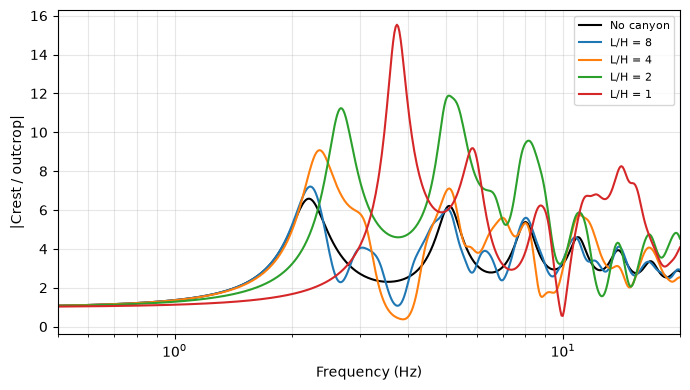

In [3]:
freqs = np.geomspace(0.5, 20, 500)
profiles = {r: make_profile(r) for r in [None, *RATIOS]}
tfs = {r: np.abs(p.transfer_function(freqs)) for r, p in profiles.items()}

fig, ax = plt.subplots(figsize=(7, 4))
for k, r in enumerate([None, *RATIOS]):
    ax.plot(freqs, tfs[r], color="k" if r is None else f"C{k - 1}", label=label(r))
ax.set(
    xscale="log", xlim=(0.5, 20), xlabel="Frequency (Hz)", ylabel="|Crest / outcrop|"
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

f_2d, a_2d = first_peak(freqs, tfs[None])
rows = []
for r in [None, *RATIOS]:
    f1, a1 = first_peak(freqs, tfs[r])
    rows.append(
        {
            "L/H": np.inf if r is None else r,
            "f1 (Hz)": f1,
            "peak": a1,
            "f1 shift": f1 / f_2d - 1,
            "peak change": a1 / a_2d - 1,
        }
    )
pd.DataFrame(rows).round(3)

## Natural frequencies

On a rigid base the first frequency of the dam in a canyon is $f = \sqrt{f_n^2 + (j V_s / 2 L)^2}$, where $f_n$ is the frequency of mode $n$ of the dam of infinite length and $j$ is the longitudinal mode, 1 for the fundamental. `canyon_rect_natural_freqs` is that closed form, for the truncated wedge of this dam. The figure shows the ratio to the frequencies without a canyon for the first three vertical modes, with the first peak of the transfer functions above, which includes the elastic rock, as points.

The canyon matters most for the first mode: the longitudinal term is the same for every mode, but it is small next to the higher frequencies.

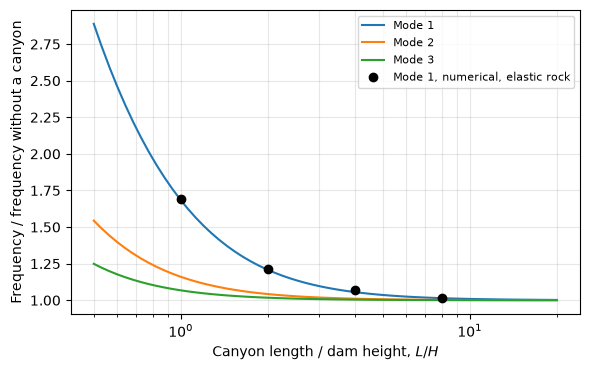

In [4]:
crest_offset = profiles[None].crest_offset
f_inf = analytical.wedge_truncated_natural_freqs(HEIGHT, VEL, crest_offset, n=3)

ratios = np.geomspace(0.5, 20, 60)
f_canyon = np.array(
    [
        dam.canyon_rect_natural_freqs(
            HEIGHT, VEL, r * HEIGHT, n=3, crest_offset=crest_offset
        )
        for r in ratios
    ]
)

fig, ax = plt.subplots(figsize=(6, 3.8))
for mode in range(3):
    ax.plot(ratios, f_canyon[:, mode] / f_inf[mode], label=f"Mode {mode + 1}")
ax.plot(
    RATIOS,
    [first_peak(freqs, tfs[r])[0] / f_2d for r in RATIOS],
    "ko",
    label="Mode 1, numerical, elastic rock",
)
ax.set(
    xscale="log",
    xlabel="Canyon length / dam height, $L / H$",
    ylabel="Frequency / frequency without a canyon",
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

## Variation along the crest

The abutments move with the input, so the transfer function is 1 at the end of the crest. It grows toward the center, where the response is largest. For $L / H = 4$ the map shows the transfer function at the crest against the position and the frequency, and the line shows the position at the first resonance, the longitudinal mode shape of the dam.

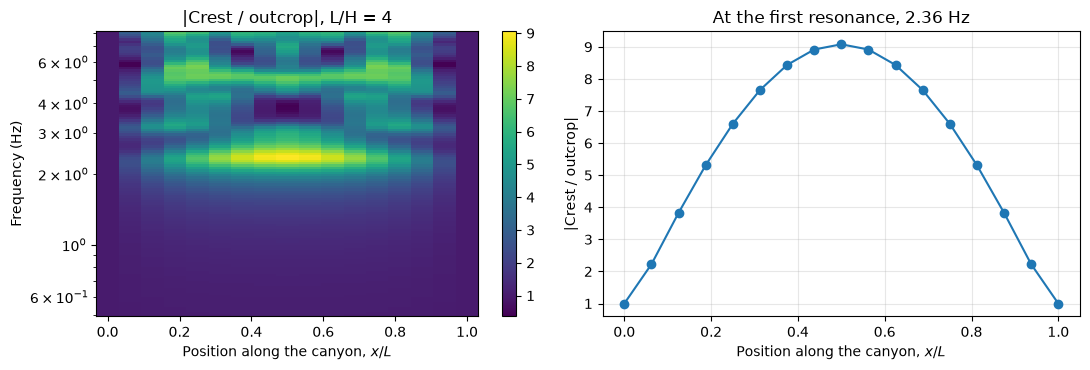

In [5]:
ratio = 4
length = ratio * HEIGHT
fr = np.geomspace(0.5, 8, 120)
p4 = make_profile(ratio, f_max=8.0)
xs = np.linspace(0, length, 17)
amp = np.array([np.abs(p4.transfer_function(fr, x=x)) for x in xs])
f1, _ = first_peak(freqs, tfs[ratio])
amp_f1 = np.array([np.abs(p4.transfer_function([f1], x=x))[0] for x in xs])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
mesh = axes[0].pcolormesh(xs / length, fr, amp.T, shading="auto", cmap="viridis")
axes[0].set(
    yscale="log",
    xlabel="Position along the canyon, $x / L$",
    ylabel="Frequency (Hz)",
    title=f"|Crest / outcrop|, L/H = {ratio}",
)
fig.colorbar(mesh, ax=axes[0])
axes[1].plot(xs / length, amp_f1, "C0o-")
axes[1].set(
    xlabel="Position along the canyon, $x / L$",
    ylabel="|Crest / outcrop|",
    title=f"At the first resonance, {f1:.2f} Hz",
)
axes[1].grid(True, alpha=0.3)
fig.tight_layout()

## Equivalent-linear response

The dam is nonlinear: the modulus reduction and damping curves of Example 20 for the rockfill, and the NIS090 motion scaled to 0.5 g. The equivalent-linear strain of each layer is the peak of $\sqrt{\gamma_{rz}^2 + \gamma_{xy}^2}$, the shear strain in the section and the longitudinal one along the axis of the dam, at the center of the canyon. A shorter canyon stiffens the dam, which puts its resonance in the band of strong shaking.

These runs use 12 layers, and 10 modes of the canyon, which is enough at the center.

In [6]:
strains = np.logspace(-5, -1, 9)
mod_reduc = site.ModulusReductionCurve(
    "rockfill", strains, [1.0, 0.99, 0.95, 0.85, 0.65, 0.4, 0.2, 0.1, 0.05]
)
damping_curve = site.DampingCurve(
    "rockfill", strains, [0.02, 0.025, 0.035, 0.06, 0.09, 0.13, 0.17, 0.2, 0.22]
)
fill_nl = site.SoilType("rockfill", 21.0, mod_reduc, damping_curve)
motion = pystrata.motion.TimeSeriesMotion.load_at2_file("data/NIS090.AT2", scale=0.5)

eql_ratios = [None, 4, 2]
eql = {}
rows = []
for r in eql_ratios:
    # The center of the canyon is converged with few modes
    p = make_profile(r, soil=fill_nl, n_layers=12, n_modes=10)
    calc = dam.DamEquivalentLinearCalculator()
    loc_input = p.location("outcrop", index=len(p) - 1)
    calc(motion, p, loc_input)
    crest = p.location("within", depth=0.0)
    eql[r] = (p, calc, loc_input)
    rows.append(
        {
            "L/H": np.inf if r is None else r,
            "crest PGA (g)": motion.calc_peak(calc.calc_accel_tf(loc_input, crest)),
            "max strain (%)": 100 * max(layer.strain_max for layer in p[:12]),
            "min G/Gmax": min(layer.shear_mod_reduc for layer in p[:12]),
        }
    )
print(f"Input PGA: {motion.pga:.3f} g")
pd.DataFrame(rows).round(3)

Input PGA: 0.251 g


,L/H,crest PGA (g),max strain (%),min G/Gmax
0,inf,0.780,0.093,0.738
1,4.0,0.815,0.125,0.686
2,2.0,1.106,0.128,0.682


### Strain along the crest

The strains of the equivalent-linear properties at three positions along the canyon, with the strain-compatible properties of the center. $\gamma_{rz}$ is largest where the response is, and the longitudinal strain $\gamma_{xy} = \partial u / \partial x$ is zero at the center by symmetry and largest near the abutments, where the dam is held.

,L/H,x/L,max gamma_rz (%),max gamma_xy (%),gamma_xy at the crest (%)
0,4,0.50,0.125,0.000,0.000
1,4,0.25,0.089,0.060,0.060
2,4,0.05,0.038,0.080,0.080
3,2,0.50,0.128,0.000,0.000
4,2,0.25,0.095,0.098,0.098
5,2,0.05,0.025,0.145,0.145


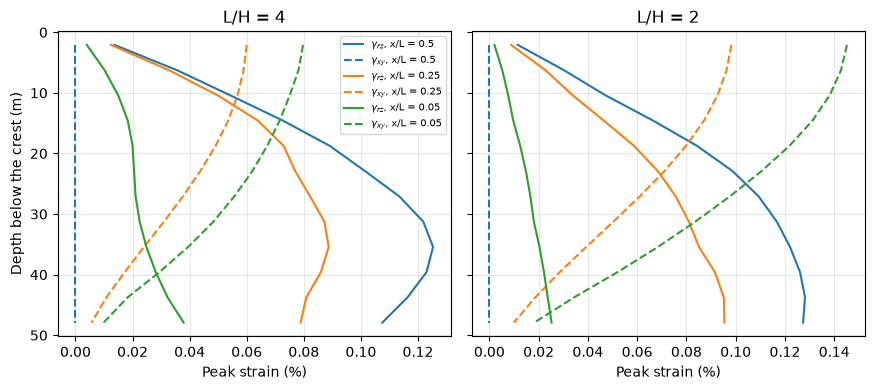

In [7]:
from pystrata.site import Location


def peak_strains(ratio, x_frac):
    # Linear-elastic response at a position, with the strain-compatible properties
    # that the equivalent-linear calculation left in the layers
    p, _, loc_input = eql[ratio]
    calc = dam.DamLinearElasticCalculator()
    calc.canyon_x = x_frac * ratio * HEIGHT
    calc(motion, p, loc_input, reset_layers=False)
    depths, g_rz, g_xy = [], [], []
    for i, layer in enumerate(p[:12]):
        loc = Location(i, layer, "within", layer.thickness / 2)
        depths.append(layer.depth + layer.thickness / 2)
        for tf, out in [
            (calc.calc_strain_tf(loc_input, loc), g_rz),
            (calc.calc_strain_xy_tf(loc_input, loc), g_xy),
        ]:
            out.append(np.abs(motion.calc_time_series(tf)).max())
    return np.array(depths), 100 * np.array(g_rz), 100 * np.array(g_xy)


rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, r in zip(axes, eql_ratios[1:]):
    for k, frac in enumerate([0.5, 0.25, 0.05]):
        depths, g_rz, g_xy = peak_strains(r, frac)
        rows.append(
            {
                "L/H": r,
                "x/L": frac,
                "max gamma_rz (%)": g_rz.max(),
                "max gamma_xy (%)": g_xy.max(),
                "gamma_xy at the crest (%)": g_xy[0],
            }
        )
        ax.plot(g_rz, depths, f"C{k}-", label=f"$\\gamma_{{rz}}$, x/L = {frac}")
        ax.plot(g_xy, depths, f"C{k}--", label=f"$\\gamma_{{xy}}$, x/L = {frac}")
    ax.set(xlabel="Peak strain (%)", title=f"L/H = {r}")
    ax.grid(True, alpha=0.3)
axes[0].set(ylabel="Depth below the crest (m)")
axes[0].invert_yaxis()
axes[0].legend(fontsize=7)
fig.tight_layout()
pd.DataFrame(rows).round(3)

## Sliding mass

The transfer function of the sliding mass of Hale and Abrahamson (Example 21) is the average acceleration of the mass inside the circle through the toe of the dam. In a canyon the mass is taken to span the length of the canyon, so the transfer function is averaged along it as well: the part near the abutments moves like the input and lowers the average.

,L/H,f1 (Hz),peak
0,inf,2.146,3.677
1,4.0,2.249,3.432
2,2.0,2.590,4.082
3,1.0,3.772,5.417


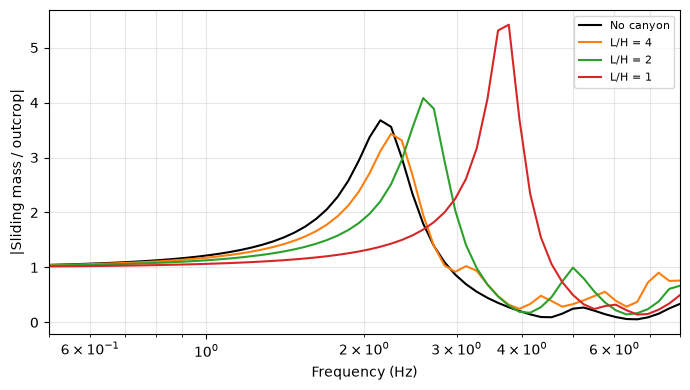

In [8]:
fs = np.geomspace(0.5, 8, 60)
surface = dam.toe_circle(profiles[None].dam)
slide = {}
for r in [None, *RATIOS[1:]]:
    p = make_profile(r, f_max=8.0)
    slide[r] = np.abs(p.sliding_mass_transfer_function(fs, surface, n_depths=41, n_x=5))

fig, ax = plt.subplots(figsize=(7, 4))
for k, r in enumerate([None, *RATIOS[1:]]):
    ax.plot(fs, slide[r], color="k" if r is None else f"C{k}", label=label(r))
ax.set(
    xscale="log",
    xlim=(0.5, 8),
    xlabel="Frequency (Hz)",
    ylabel="|Sliding mass / outcrop|",
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

rows = []
for r, tf in slide.items():
    f1, a1 = first_peak(fs, tf)
    rows.append({"L/H": np.inf if r is None else r, "f1 (Hz)": f1, "peak": a1})
pd.DataFrame(rows).round(3)

### Observations

- **A shorter canyon raises the first frequency and the amplification.** The first peak of the crest at the center moves from 2.21 Hz without a canyon to 2.24, 2.36, 2.68 and 3.74 Hz for $L / H$ of 8, 4, 2 and 1: 2%, 7%, 21% and 69% higher. Its amplitude grows by 10%, 38%, 71% and 136%. A canyon eight times the height of the dam is almost the dam of infinite length, but one two times the height is not.
- **The closed form predicts the shift.** The rigid-base frequencies of `canyon_rect_natural_freqs` and the numerical peaks on elastic rock agree closely, so the ratio of the first frequency to the one without a canyon, $\sqrt{1 + (j V_s / 2 L f_n)^2}$, is a good first estimate. The higher modes are shifted less, because the longitudinal term does not depend on the mode.
- **The response is 1 at the abutments and peaks at the center.** For $L / H = 4$ the first resonance, at 2.36 Hz, has an amplitude of 9.1 at the center and 1 at the end of the crest, close to half a sine wave. The higher frequencies have more nodes along the crest.
- **The equivalent-linear response grows in a short canyon.** For an input of 0.25 g the crest PGA is 0.78 g for the dam of infinite length, 0.82 g for $L / H = 4$ and 1.11 g for $L / H = 2$, and the dam is softer: the smallest $G / G_{max}$ is 0.74, 0.69 and 0.68.
- **Near the abutments the longitudinal strain dominates.** At the center the strain is the shear strain, 0.13% for both canyons. At $x / L = 0.05$, $\gamma_{rz}$ drops to 0.04% and 0.03% for $L / H$ of 4 and 2, and $\gamma_{xy}$ at the crest is 0.08% and 0.15%, which is larger than $\gamma_{rz}$ anywhere there. The equivalent-linear properties of a layer are the same along the crest and follow the strain at the position of the calculation (the center by default), so they do not follow the change of the strain toward the abutments.
- **The sliding mass averages the response along the canyon.** The peak of the transfer function is 3.68 for the dam of infinite length, 3.43 for $L / H = 4$, 4.08 for 2 and 5.42 for 1, at 2.15, 2.25, 2.59 and 3.77 Hz. For $L / H = 4$ the center of the crest amplifies 38% more than the dam of infinite length (above), but the mass spans the abutments, where the response is low, so its average is lower. The center of the canyon overstates the sliding mass of a long canyon, and a short canyon is dominated by the stiffening.

The limits of the model are the rigid abutments that move with the outcrop, the rectangular section, and the independent columns of the site. A dam on soft ground that moves differently from the abutments, or a canyon with sloping walls, is outside them. `Dam.fixed_base_freqs` and `Dam.tune` without a site are for the dam of infinite length, and the cost of a calculation grows with the number of modes of the canyon.